<a href="https://colab.research.google.com/github/sytluc0803/MSSP607/blob/main/Modules/Week_9/Week_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import userdata
import os

github_token = userdata.get('Git_Key')
owner = 'sytluc0803'
repository = 'MSSP607'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

# Clone the repository
import subprocess
subprocess.run(['git', 'clone', clone_url])

# Navigate into the cloned repository directory (optional, but often useful)
os.chdir(repository)
print(f"Changed directory to: {os.getcwd()}")

Changed directory to: /content/MSSP607


In [3]:
%pushd "/content/MSSP607/Modules/Week_9"

/content/MSSP607/Modules/Week_9


['/content/MSSP607']

In [4]:
!pip install bs4 lxml

Reading https://sp2.upenn.edu/sp2-directory/
1. isabel-rose-algrant-mssp-da


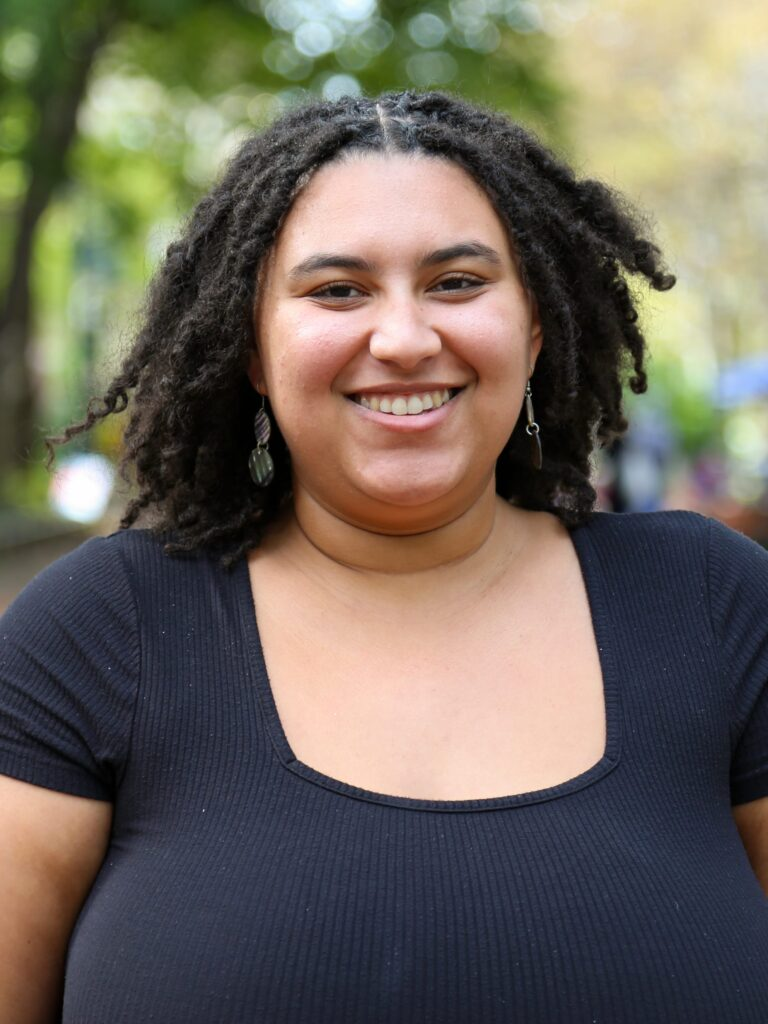

2. ayesha-amin


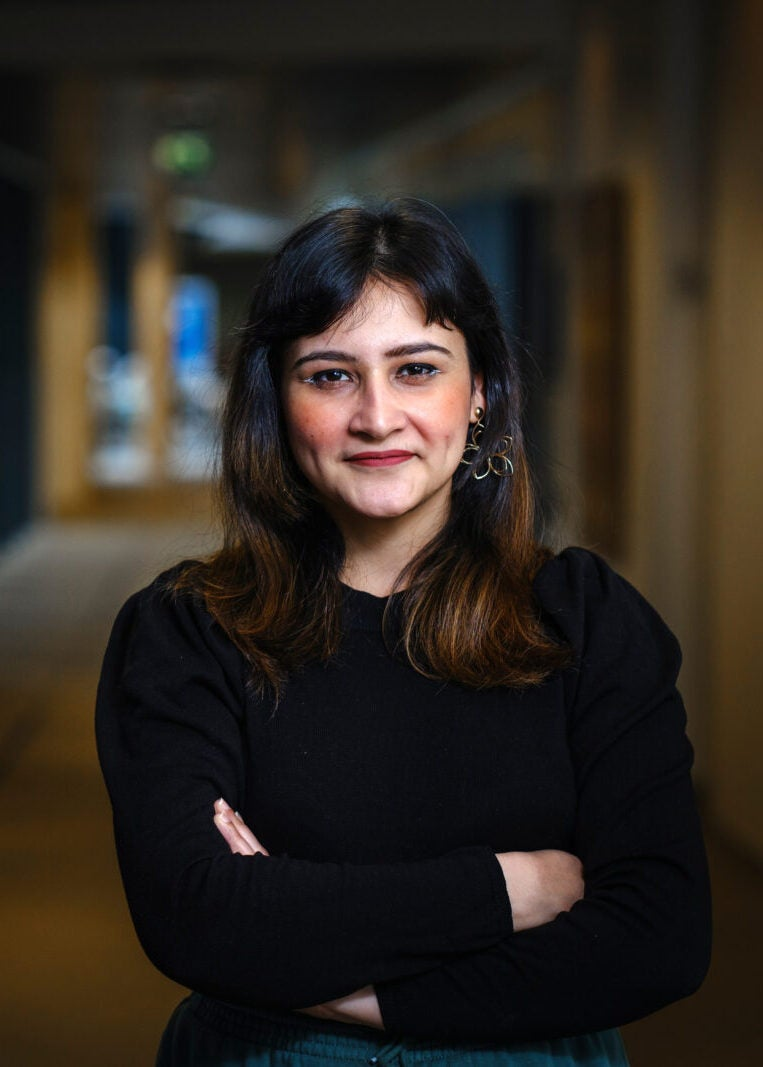

3. gina-amoroso-latta


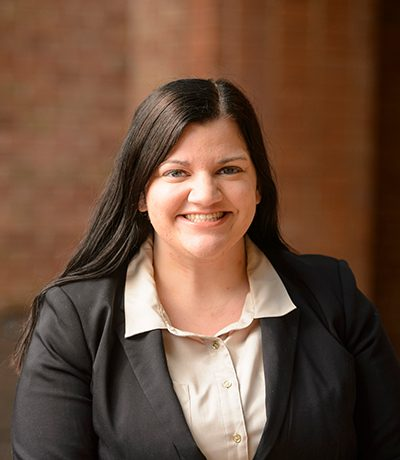

4. obed-arango


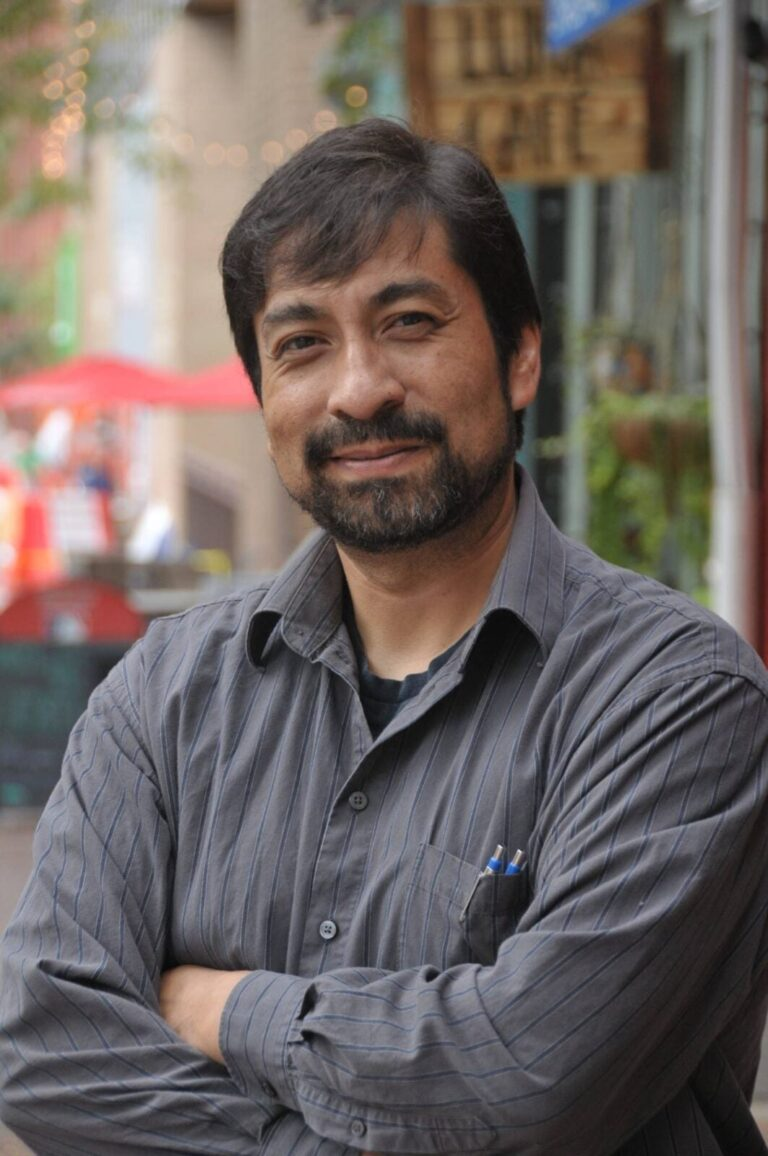

Reading https://sp2.upenn.edu/sp2-directory/page/2/
5. celene-bennett


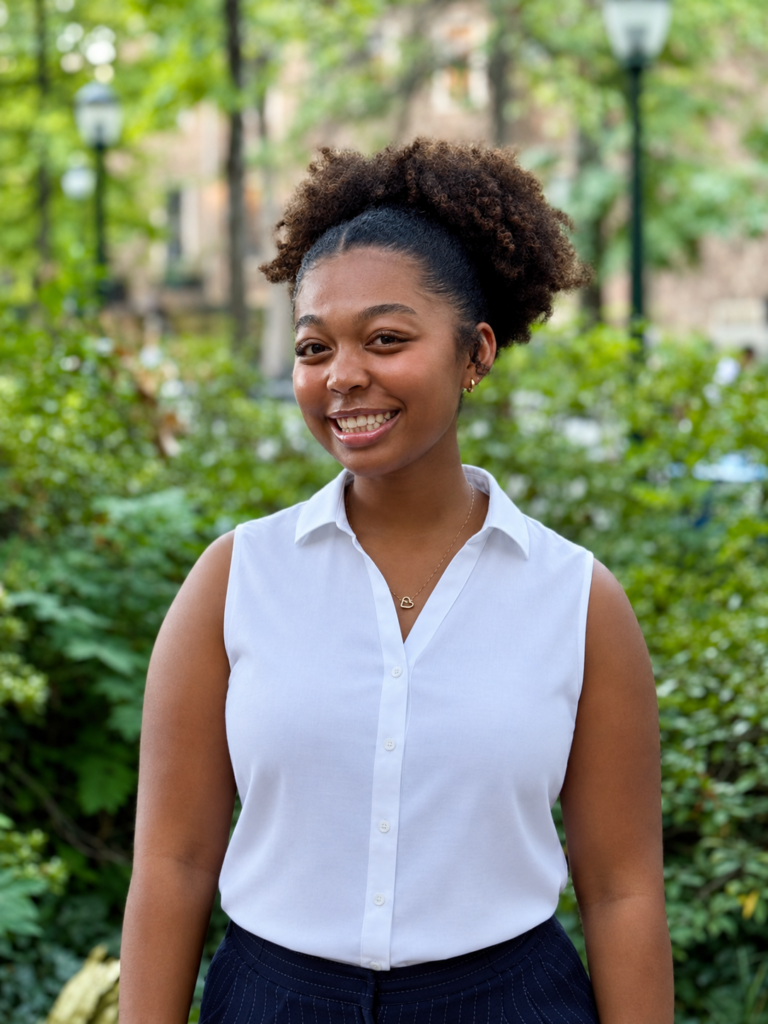

Reading https://sp2.upenn.edu/sp2-directory/page/3/
Reading https://sp2.upenn.edu/sp2-directory/page/4/
6. naimat-chopra


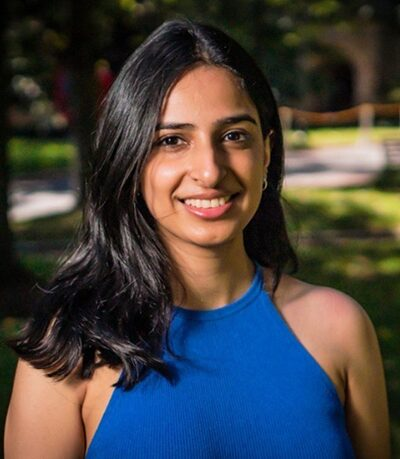

7. shweta-chopra


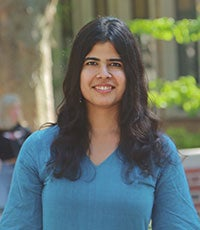

Reading https://sp2.upenn.edu/sp2-directory/page/5/
8. ben-cochran


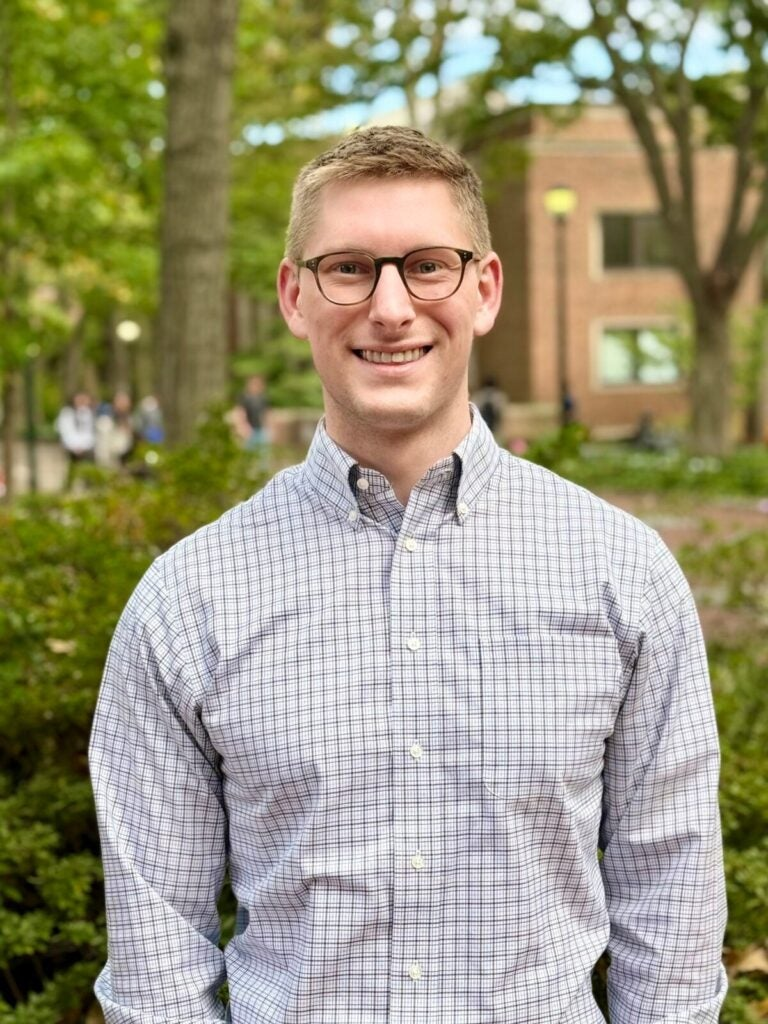

9. erin-coltrera


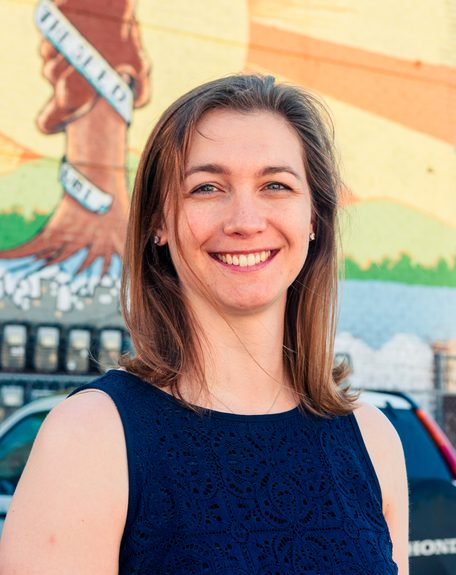

Reading https://sp2.upenn.edu/sp2-directory/page/6/
10. jim-davy


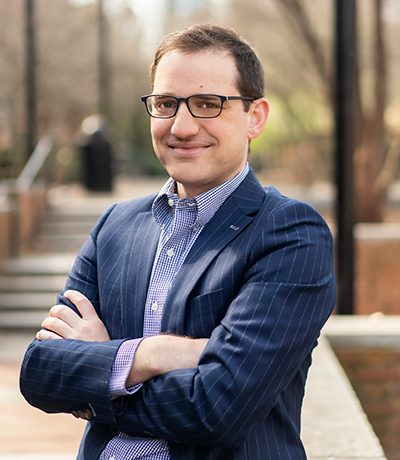

Done. 10 photos in memory.


In [10]:
import re, time
import requests, bs4
from IPython.display import display, Image

base_url = 'https://sp2.upenn.edu/sp2-directory/'
max_photos = 10
count = 0
photos = {}          # name -> image bytes, kept in memory so we can download later

def get_soup(url):
    res = requests.get(url)
    res.raise_for_status()
    return bs4.BeautifulSoup(res.content, 'lxml')

def find_photo(card, profile_url):
    img = card.find('img')
    if img is None:
        profile_soup = get_soup(profile_url)
        og = profile_soup.find('meta', {'property': 'og:image'})
        if og and 'Penn-SP2-OG' not in og['content']:
            return og['content']
        main = profile_soup.find('main')
        img = main.find('img') if main else None
    if img is None:
        return None
    src = img.get('data-src') or img.get('src')
    if not src or src.startswith('data:') or 'logo' in src.lower():
        return None
    return src

page = 1
while count < max_photos and page <= 28:
    url = base_url if page == 1 else base_url + 'page/' + str(page) + '/'
    print('Reading', url)
    soup = get_soup(url)
    links = soup.find_all('a', href=re.compile(r'/sp2-directory/[^/]+/$'))

    for card in links:
        if count >= max_photos:
            break
        profile_url = card['href']
        name_slug = profile_url.rstrip('/').split('/')[-1]

        if 'MSSP' not in card.get_text(' ', strip=True) or name_slug == 'page':
            continue

        photo_url = find_photo(card, profile_url)
        if photo_url is None:
            print('No photo for', name_slug)
            continue

        res = requests.get(photo_url)
        res.raise_for_status()
        photos[name_slug] = res.content            # keep the bytes
        print(f'{count + 1}. {name_slug}')
        display(Image(data=res.content, width=200))

        count += 1
        time.sleep(1)

    page += 1

print('Done.', count, 'photos in memory.')

In [11]:
import io, zipfile
from PIL import Image as PILImage
from google.colab import files

def to_jpg_bytes(data):
    """Open the image bytes with PIL and re-save as a real .jpg."""
    buffer = io.BytesIO()
    PILImage.open(io.BytesIO(data)).convert('RGB').save(buffer, format='JPEG')
    return buffer.getvalue()

with zipfile.ZipFile('sp2_photos.zip', 'w') as z:
    for name, data in photos.items():
        z.writestr(name + '.jpg', to_jpg_bytes(data))

files.download('sp2_photos.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>